# 03 — Results analysis
Builds every table (`results/tables/`) and figure (`results/figures/`) from `results/runs.csv`.
`TAGS` comes from the environment variable TAGS (default `main`, the final protocol; `prelim` for the progress-report numbers).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
%matplotlib inline
print("project root:", ROOT)

project root: <repo>


In [2]:
import pandas as pd
from src import analysis, data
pd.set_option("display.width", 220)
import os
TAGS = os.environ.get("TAGS", "main").split(",")  # "prelim" for the progress-report numbers
runs = analysis.load_runs(tags=TAGS)
print(len(runs), "runs"); runs.groupby(["model", "features", "protocol", "tag"]).size()

99 runs


model  features  protocol  tag 
m1     logmel    actor     main    18
                 random    main     3
       mfcc      actor     main    18
m2     logmel    actor     main    18
                 random    main     3
m3     logmel    actor     main    18
                 random    main     3
m4     wave      actor     main    18
dtype: int64

## Main table (mean ± std over folds × seeds, %)

In [3]:
analysis.summary_table(runs, name='results_' + '_'.join(TAGS))

,model,features,protocol,tag,n_runs,folds,seeds,UAR (%),Accuracy (%),Macro-F1 (%),val UAR (%),params,trainable,mean train time (s),mean best epoch
0,M1 BiLSTM+Att,logmel,actor,main,18,6,3,56.10 ± 4.40,57.08 ± 4.97,55.60 ± 4.66,60.63 ± 4.46,2241032,2241032,130.6,42.1
1,M1 BiLSTM+Att,logmel,random,main,3,1,3,76.69 ± 2.22,76.94 ± 2.29,76.27 ± 2.43,84.64 ± 1.85,2241032,2241032,201.3,71.0
2,M1 BiLSTM+Att,mfcc,actor,main,18,6,3,56.79 ± 2.51,57.43 ± 3.17,55.89 ± 3.18,60.09 ± 3.10,2355720,2355720,97.4,26.3
3,M2 CNN-BiLSTM,logmel,actor,main,18,6,3,63.72 ± 4.94,64.38 ± 5.04,63.22 ± 4.99,66.78 ± 4.79,2723048,2723048,54.9,40.7
4,M2 CNN-BiLSTM,logmel,random,main,3,1,3,75.26 ± 3.41,75.56 ± 3.59,74.53 ± 3.65,81.77 ± 3.32,2723048,2723048,70.0,54.7
5,M3 Transformer,logmel,actor,main,18,6,3,53.73 ± 4.33,55.23 ± 4.27,52.89 ± 4.28,57.77 ± 4.51,1368840,1368840,16.0,29.6
6,M3 Transformer,logmel,random,main,3,1,3,70.83 ± 5.49,71.39 ± 5.28,70.13 ± 5.71,80.60 ± 2.60,1368840,1368840,27.3,57.3
7,M4 wav2vec2-base,wave,actor,main,18,6,3,75.00 ± 4.81,75.60 ± 4.61,74.62 ± 4.87,79.08 ± 3.22,94377864,90177416,298.0,22.3


In [4]:
analysis.per_class_recall_table(runs, name='per_class_recall_' + '_'.join(TAGS))

,model,features,protocol,tag,neutral,calm,happy,sad,angry,fearful,disgust,surprised
0,M1 BiLSTM+Att,logmel,actor,main,41.3 ± 13.1,63.4 ± 19.0,54.5 ± 14.1,48.4 ± 13.2,75.2 ± 11.5,45.7 ± 15.2,69.1 ± 17.6,51.2 ± 13.3
1,M1 BiLSTM+Att,logmel,random,main,72.9 ± 7.2,86.5 ± 4.8,67.7 ± 7.2,69.8 ± 4.8,86.5 ± 3.6,70.8 ± 11.0,83.3 ± 4.8,76.0 ± 7.9
2,M1 BiLSTM+Att,mfcc,actor,main,47.2 ± 19.9,67.9 ± 15.6,51.0 ± 10.8,31.9 ± 13.7,72.9 ± 9.9,53.1 ± 16.6,61.1 ± 15.5,69.1 ± 14.2
3,M2 CNN-BiLSTM,logmel,actor,main,53.8 ± 17.2,73.4 ± 17.2,57.1 ± 14.9,41.8 ± 16.3,82.1 ± 7.3,60.9 ± 16.2,72.7 ± 14.9,67.7 ± 19.1
4,M2 CNN-BiLSTM,logmel,random,main,70.8 ± 3.6,87.5 ± 3.1,60.4 ± 4.8,65.6 ± 14.3,89.6 ± 1.8,61.5 ± 3.6,90.6 ± 3.1,76.0 ± 4.8
5,M3 Transformer,logmel,actor,main,31.2 ± 17.7,69.8 ± 20.6,45.7 ± 15.9,41.7 ± 15.8,66.7 ± 12.3,49.7 ± 16.7,66.7 ± 18.1,58.5 ± 17.0
6,M3 Transformer,logmel,random,main,62.5 ± 10.8,84.4 ± 0.0,62.5 ± 5.4,60.4 ± 20.3,85.4 ± 3.6,62.5 ± 3.1,80.2 ± 4.8,68.8 ± 6.2
7,M4 wav2vec2-base,wave,actor,main,66.0 ± 14.9,85.1 ± 13.5,71.7 ± 11.7,57.6 ± 16.1,84.5 ± 7.3,67.9 ± 16.4,86.5 ± 10.4,80.7 ± 13.6


## Confusion matrices (pooled over all test predictions)

,group,true,pred,count,rate
0,m1_logmel_actor_main,neutral,sad,50,0.173611
1,m1_logmel_actor_main,neutral,calm,49,0.170139
2,m1_logmel_actor_main,fearful,sad,98,0.170139
3,m1_logmel_actor_main,calm,sad,97,0.168403
4,m1_logmel_actor_main,sad,calm,79,0.137153
5,m1_logmel_random_main,neutral,calm,7,0.145833
6,m1_logmel_random_main,happy,neutral,14,0.145833
7,m1_logmel_random_main,fearful,happy,12,0.125000
8,m1_logmel_random_main,surprised,happy,12,0.125000
9,m1_logmel_random_main,fearful,sad,9,0.093750


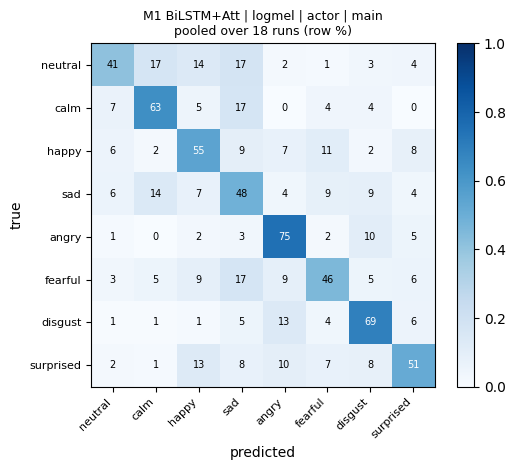

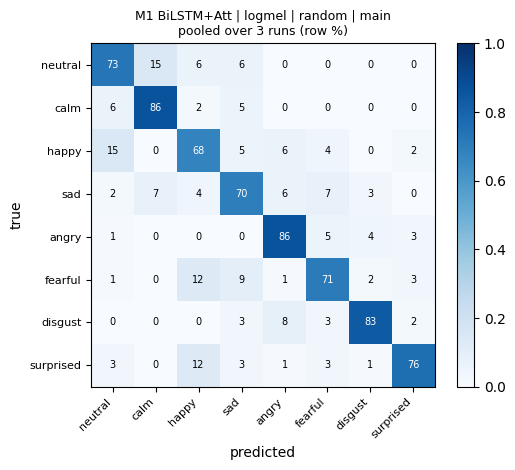

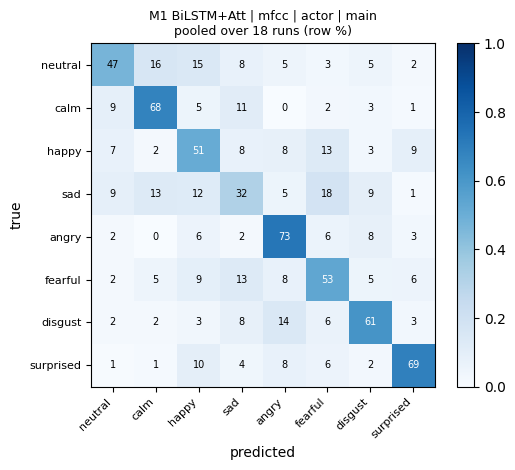

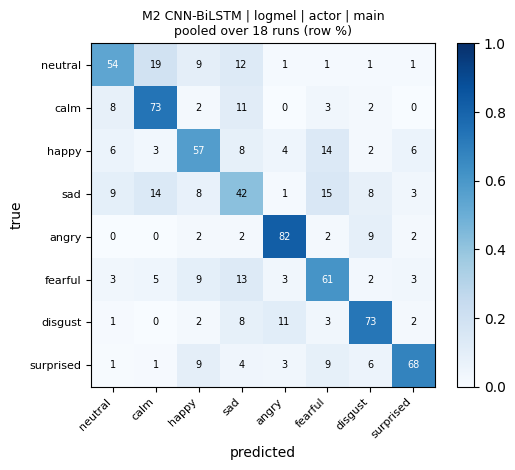

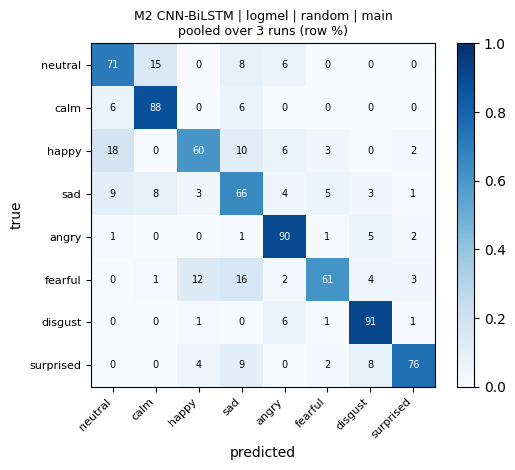

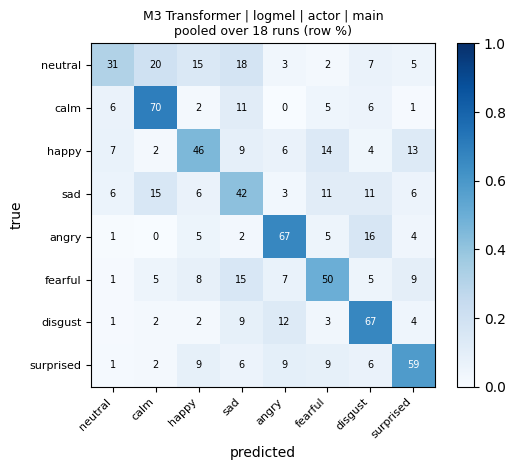

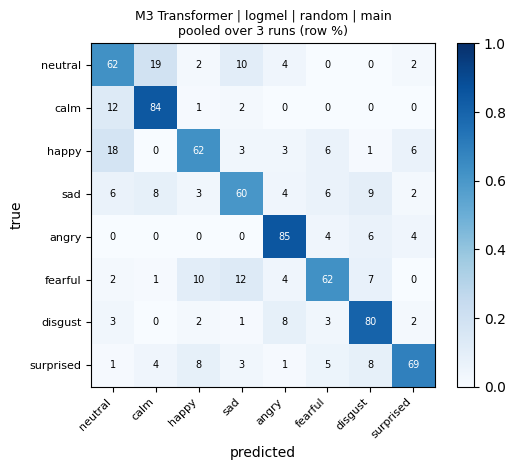

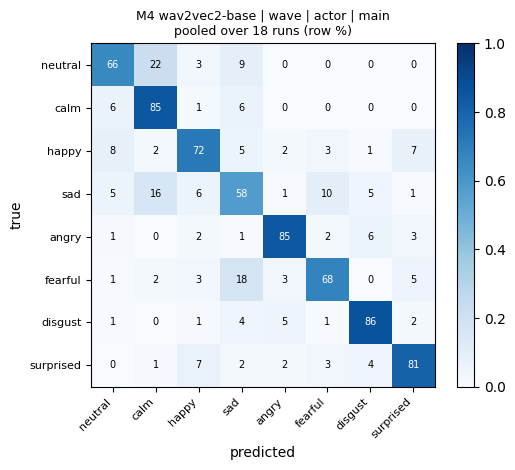

In [5]:
cms = analysis.confusion_figures(runs, name='top_confusions_' + '_'.join(TAGS))
pd.DataFrame([{"group": k, **r} for k, v in cms.items() for r in v["top"]])

## Training / validation curves

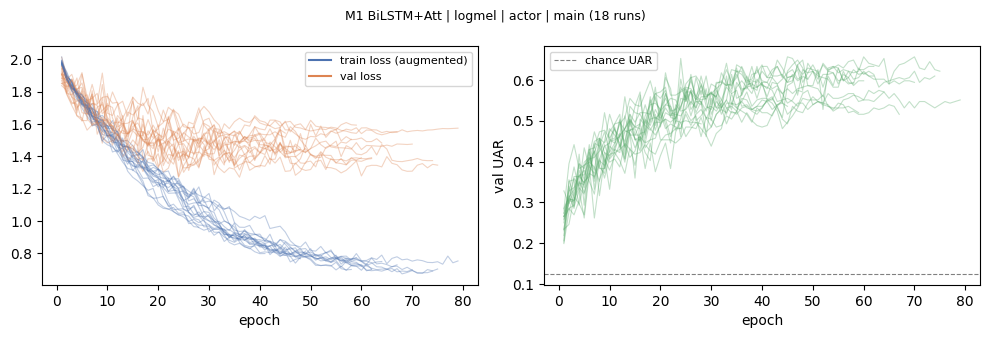

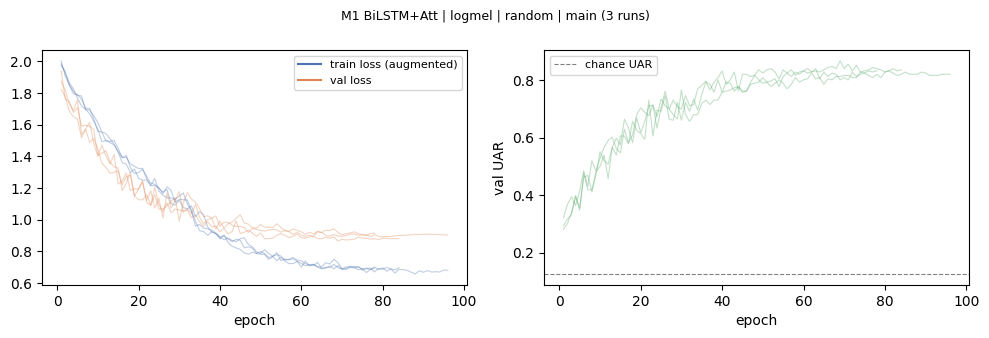

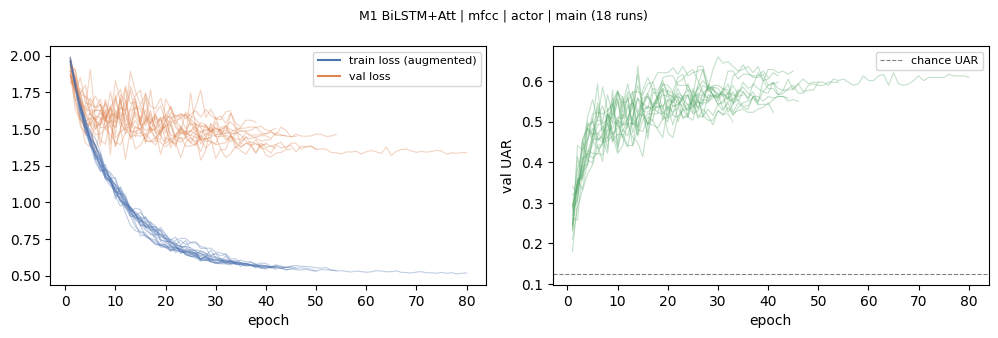

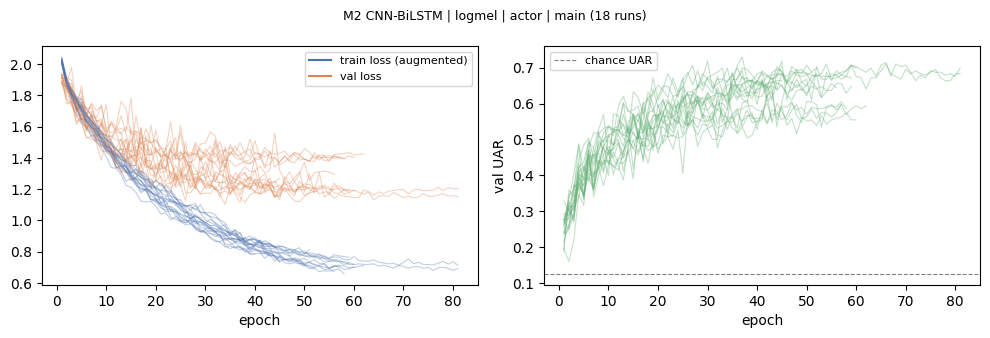

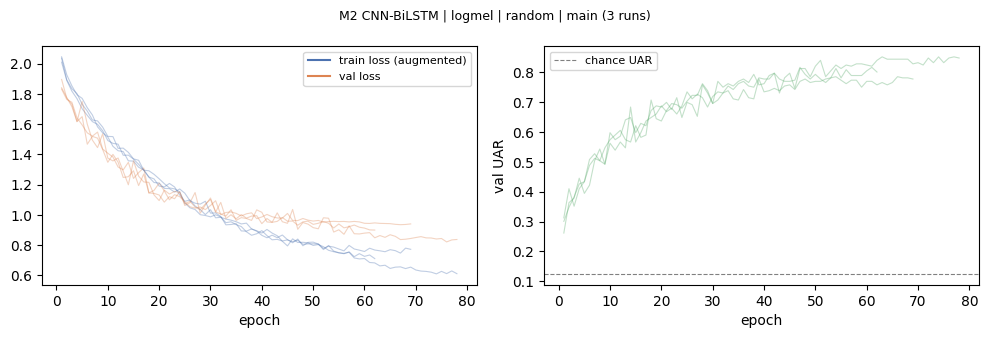

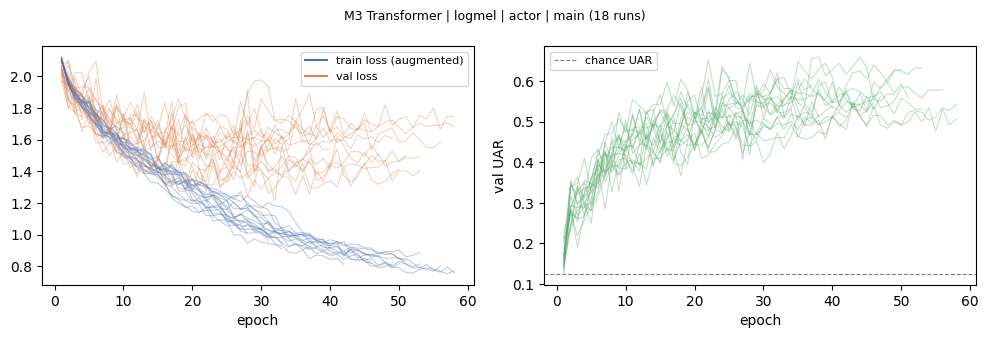

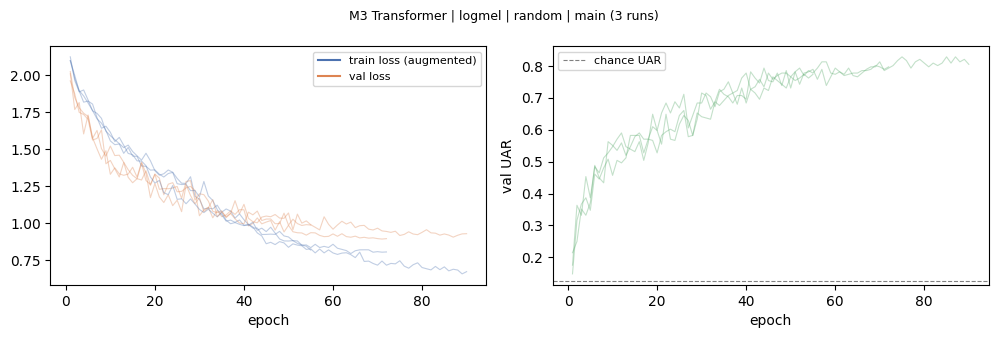

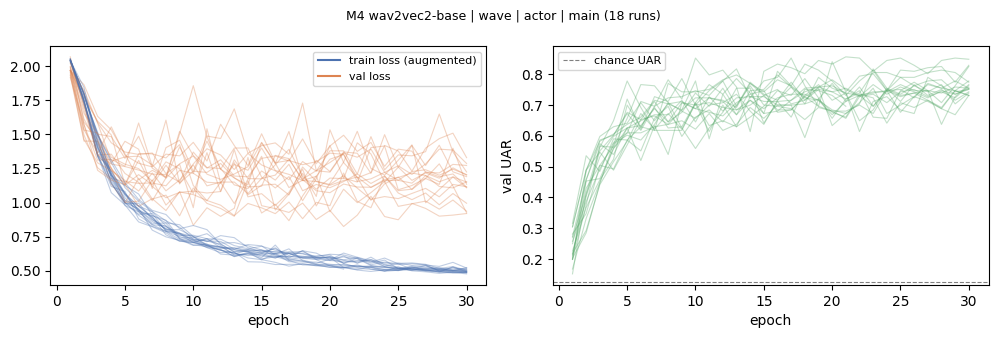

In [6]:
analysis.plot_curves(runs);

## Paired statistical tests (same folds & seeds)

In [7]:
analysis.stats_tests(runs, tag=TAGS[0]) if runs['model'].nunique() > 1 else 'need >= 2 models'

,A,B,n,mean_a,mean_b,mean_diff,std_diff,t,t_p,wilcoxon_W,wilcoxon_p,level,t_p_holm,wilcoxon_p_holm
0,m1/logmel,m1/mfcc,6,0.560981,0.567925,-0.006944,0.033295,-0.510893,6.311773e-01,8.0,0.687500,fold,6.311773e-01,0.687500
1,m1/logmel,m1/mfcc,18,0.560981,0.567925,-0.006944,0.043344,-0.679739,5.058213e-01,77.0,0.710692,run,5.058213e-01,0.710692
2,m1/logmel,m2/logmel,6,0.560981,0.637153,-0.076172,0.012831,-14.541924,2.776121e-05,0.0,0.031250,fold,2.498509e-04,0.312500
3,m1/logmel,m2/logmel,18,0.560981,0.637153,-0.076172,0.039638,-8.152940,2.817684e-07,1.0,0.000232,run,1.408842e-06,0.001937
4,m1/logmel,m3/logmel,6,0.560981,0.537326,0.023655,0.040069,1.446051,2.077968e-01,5.0,0.312500,fold,4.155936e-01,0.625000
5,m1/logmel,m3/logmel,18,0.560981,0.537326,0.023655,0.051413,1.951984,6.761241e-02,44.0,0.070576,run,1.352248e-01,0.141152
6,m1/logmel,m4/wave,6,0.560981,0.750000,-0.189019,0.027602,-16.774211,1.376248e-05,0.0,0.031250,fold,1.376248e-04,0.312500
7,m1/logmel,m4/wave,18,0.560981,0.750000,-0.189019,0.035955,-22.304024,5.001612e-14,0.0,0.000194,run,5.001612e-13,0.001937
8,m1/mfcc,m2/logmel,6,0.567925,0.637153,-0.069227,0.042992,-3.944288,1.091294e-02,1.0,0.062500,fold,4.365174e-02,0.312500
9,m1/mfcc,m2/logmel,18,0.567925,0.637153,-0.069227,0.053187,-5.522206,3.731401e-05,8.5,0.001278,run,1.492560e-04,0.005113


## Feature ablation (M1: log-mel vs MFCC)  and  leakage diagnostic (Q3)

In [8]:
display(analysis.ablation_table(runs, tag=TAGS[0]))
display(analysis.leakage_table(runs, tag=TAGS[0]))

,features,n,UAR (%),Accuracy (%),Macro-F1 (%)
0,logmel,18,56.10 ± 4.40,57.08 ± 4.97,55.60 ± 4.66
1,mfcc,18,56.79 ± 2.51,57.43 ± 3.17,55.89 ± 3.18


,model,actor-wise UAR (%),n_actor,random-split UAR (%),n_random,inflation UAR (points),inflation acc (points)
0,M1 BiLSTM+Att,56.10 ± 4.40,18,76.69 ± 2.22,3,20.59,19.86
1,M2 CNN-BiLSTM,63.72 ± 4.94,18,75.26 ± 3.41,3,11.55,11.18
2,M3 Transformer,53.73 ± 4.33,18,70.83 ± 5.49,3,17.10,16.16


## Hyper-parameter search plots (template section 5.4)

In [9]:
analysis.hparam_plots()

,model,train.lr,model.dropout,model.hidden,model.n_layers,model.n_heads
0,m1_logmel,0.002,0.3,256,NaN,NaN
1,m2_logmel,0.001,0.2,256,NaN,NaN
2,m3_logmel,0.001,0.2,NaN,2,8
3,m4_wave,5e-05,NaN,NaN,NaN,NaN


## Trivial baselines

In [10]:
analysis.baseline_table(data.load_metadata(), data.load_splits())

test_acc            test_uar           test_macro_f1          
                    mean       std      mean       std          mean       std
baseline                                                                      
majority        0.133333  0.000000  0.125000  0.000000      0.029412  0.000000
prior_random    0.116667  0.012360  0.115234  0.013700      0.114206  0.012924
uniform_random  0.115278  0.014829  0.120443  0.015112      0.114413  0.013904

## Final-report extras (variance across seeds vs folds, optimal hyper-parameters, key numbers)


In [11]:
from src import final_analysis
extras = final_analysis.extras(runs, TAGS[0])
for k, v in extras.items():
    print(k); display(v)


variance


,model,features,n_runs,mean UAR (%),std over all runs (pts),"std across folds, seed-averaged (pts)",mean std across seeds within a fold (pts),min fold UAR (%),max fold UAR (%)
0,M1 BiLSTM+Att,logmel,18,56.10,4.40,3.79,2.75,50.39,60.03
1,M1 BiLSTM+Att,mfcc,18,56.79,2.51,0.96,2.41,55.34,57.81
2,M2 CNN-BiLSTM,logmel,18,63.72,4.94,4.75,2.35,55.99,68.75
3,M3 Transformer,logmel,18,53.73,4.33,4.08,2.26,48.31,60.29
4,M4 wav2vec2-base,wave,18,75.00,4.81,4.58,2.23,70.83,83.46


hparams


,model,hyper-parameter,values searched,default,selected (val UAR),val UAR default (%),val UAR selected (%),rounds x seeds
0,m1_logmel,train.lr,"0.0005, 0.001, 0.002",0.001,0.002,58.40,58.98,6 x 1
1,m1_logmel,model.dropout,"0.2, 0.3, 0.5",0.3,0.3,58.40,58.40,6 x 1
2,m1_logmel,model.hidden,"64, 128, 256",128,256,58.40,61.91,6 x 1
3,m2_logmel,train.lr,"0.0005, 0.001, 0.002",0.001,0.001,64.91,64.91,6 x 1
4,m2_logmel,model.dropout,"0.2, 0.3, 0.5",0.3,0.2,64.91,64.97,6 x 1
5,m2_logmel,model.hidden,"64, 128, 256",128,256,64.91,65.69,6 x 1
6,m3_logmel,train.lr,"0.00025, 0.0005, 0.001",0.0005,0.001,57.10,57.62,6 x 1
7,m3_logmel,model.dropout,"0.1, 0.2, 0.3",0.3,0.2,57.10,57.16,6 x 1
8,m3_logmel,model.n_layers,"2, 4, 6",4,2,57.10,57.94,6 x 1
9,m3_logmel,model.n_heads,"2, 4, 8",4,8,57.10,57.68,6 x 1
